# AH2179 Traffic project — 01: Cleaning, preprocessing, EDA and feature engineering

**Data:** Trafikverket MCS microwave sensors, E4 Essingeleden southbound, 8 portals
(58.140 → 55.620, driving order), 1-min lane-level flow and speed, 04:00–10:00 by timestamp (06:00–10:00 local after alignment).

| File | Period | Role in this project |
|---|---|---|
| `training_dataset.csv` | 2021-06-01 – 2021-12-31 (214 days) | fit everything (model, scaler, profiles); split chronologically into *train* / *validation* |
| `evaluation_dataset.csv` | 90 days in 2022-01-01 – 2022-06-25 | test set for model comparison — never used for fitting |
| `final_evaluation_dataset.csv` | 91 *other* days in 2022-01-05 – 2022-06-30 | final hold-out; touch **once**, for the selected model |

The two 2022 files have **no dates in common** (interleaved days), so they are two independent test samples from the same period.

> ⚠️ **Time-base finding (section 2):** the lane sensors do not share a clock. IDs < 4000 (portals 57.055–55.620, except 4872/4873)
> are stamped in **UTC**, the 44xx/48xx sensors in **Swedish local time**. Without correction, portal 57.055 appears 1 h (winter) /
> 2 h (summer) "ahead" of 57.435 only 380 m upstream. All data below are aligned to local time; the window where every sensor has
> data on every day is **06:00–10:00 local**, which contains the 07:30–08:30 peak.

Every quantity estimated from data (lane shares, lane profiles, historical-average profile, scaler)
is fitted on the training file only and then *applied* to the 2022 files. The reusable logic lives in `traffic_prep.py`.

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib as mpl
import traffic_prep as tp

DATA = Path("../dataset_for_traffic_project_assignment")
OUT = Path("../processed"); OUT.mkdir(exist_ok=True)
FIG = Path("../figures"); FIG.mkdir(exist_ok=True)

RES_MIN = 5                     # aggregation step (min)
HORIZON_MIN = 15                # prediction horizon (min)
VAL_START = "2021-11-15"        # chronological train / validation cut inside the 2021 data
TARGET_WINDOW = ("07:30", "08:30")

# one colour per portal, ordered along the road (sequential: upstream = dark, downstream = light)
PCOL = {k: mpl.colormaps["viridis"](i / 7 * 0.9) for i, k in enumerate(tp.PORTALS_DOWNSTREAM)}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "font.size": 9})
def save(fig, name): fig.savefig(FIG / f"{name}.png", bbox_inches="tight", dpi=150)

## 1. Raw data audit

In [2]:
raw = {s: tp.load_raw(DATA / f"{s}_dataset.csv") for s in ["training", "evaluation", "final_evaluation"]}
audit = pd.DataFrame({s: {
    "rows": len(d), "days": d.date.nunique(), "first": d.date.min().date(), "last": d.date.max().date(),
    "sensors": d.sensor.nunique(), "portals": d.portal_km.nunique(),
    "FLOW NaN": int(d.flow.isna().sum()), "FLOW == 0": int((d.flow == 0).sum()),
    "speed < 1 m/s": int((d.speed_ms < 1).sum()), "speed > 40 m/s": int((d.speed_ms > 40).sum()),
    "rows / full grid": round(len(d) / (d.sensor.nunique() * d.date.nunique() * tp.N_MIN), 3),
} for s, d in raw.items()})
audit

,training,evaluation,final_evaluation
rows,1344924,565428,562957
days,214,90,91
first,2021-06-01,2022-01-01,2022-01-05
last,2021-12-31,2022-06-25,2022-06-30
sensors,29,29,29
portals,8,8,8
FLOW NaN,12,3,3
FLOW == 0,0,0,0
speed < 1 m/s,20,13,12
speed > 40 m/s,6,3,4


In [3]:
lanes = raw["training"].groupby("portal_km").sensor.unique().reindex(tp.PORTALS_DOWNSTREAM)
lanes.apply(lambda s: sorted(s)).to_frame("sensors (lanes)")

,sensors (lanes)
portal_km,
58.140,"[4472, 4473, 4494, 4495, 4496]"
57.820,"[4427, 4428, 4436, 4439]"
57.435,"[4429, 4430, 4437]"
57.055,"[353, 749, 1443]"
56.780,"[534, 543, 1079, 4872]"
56.490,"[153, 351, 902, 4873]"
56.160,"[536, 539, 740]"
55.620,"[751, 1076, 1254]"


**Observations**

* No duplicates, no missing values except a handful of `FLOW` NaNs (these rows all carry a placeholder speed of exactly 1.0 m/s → corrupt records).
* **There is not a single row with `FLOW = 0`.** Only ~85 % of the full sensor × minute grid is present. So a missing row can mean two very different things: *no vehicle passed* or *the sensor was down*. This is a key cleaning decision — see section 3.
* A few physically implausible speeds (< 3.6 km/h with one vehicle at 04:00, or > 144 km/h on a 70 km/h road).

## 2. Time base check — are all sensors on the same clock?

First sign: in the raw 04:00–10:00 files the mean workday flow at 04:00 is ~1 400 veh/h at the five downstream portals but
~300 veh/h at the three upstream ones, and the upstream curve looks like the downstream curve shifted by 1–2 h.
The ALL-day files let us test this directly: human routines follow *local* time, so a sensor stamped in local time has the same
daily profile in summer and winter, while a sensor stamped in UTC shifts by one hour when DST changes.

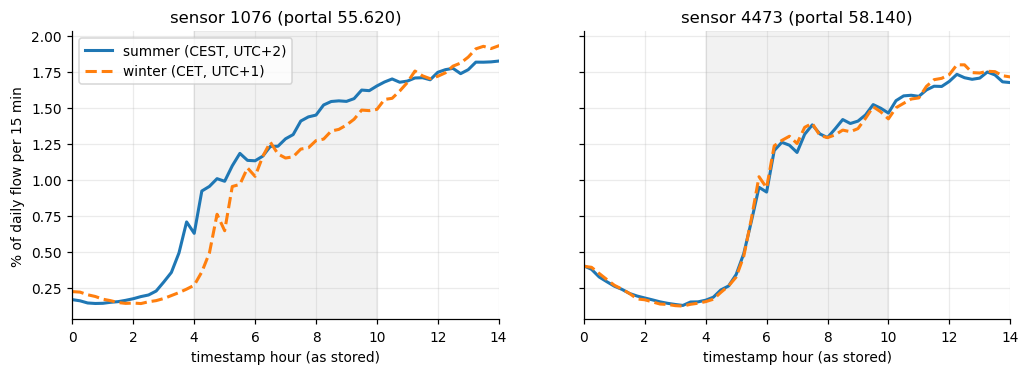

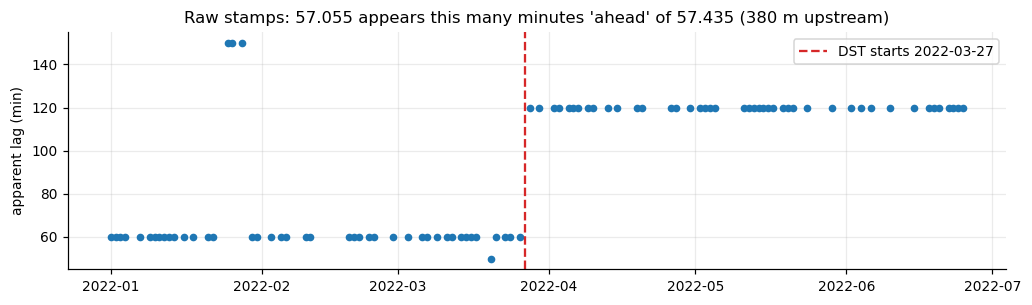

In [4]:
ALLDAY = Path("../dataset_for_traffic_project_assignment_ALLday")
a = pd.read_csv(ALLDAY / "training_dataset.csv", sep=";", usecols=["DP_ID", "Date", "Interval_1", "FLOW"])
a["season"] = np.where(a.Date < 20211031, "summer (CEST, UTC+2)", "winter (CET, UTC+1)")
a["hour"] = a.Interval_1 / 60
examples = {1076: "sensor 1076 (portal 55.620)", 4473: "sensor 4473 (portal 58.140)"}
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for axi, (sid, name) in zip(ax, examples.items()):
    for season, ls in zip(sorted(a.season.unique()), ["-", "--"]):
        p = a[(a.DP_ID == sid) & (a.season == season)].groupby(a.Interval_1 // 15 * 15 / 60).FLOW.sum()
        axi.plot(p.index, p / p.sum() * 100, ls, lw=2, label=season)
    axi.axvspan(4, 10, color="grey", alpha=.1); axi.set(title=name, xlabel="timestamp hour (as stored)", xlim=(0, 14))
ax[0].set_ylabel("% of daily flow per 15 min"); ax[0].legend()
save(fig, "02_time_base_dst"); plt.show()

# DST jump in the lag between two adjacent portals (raw stamps, 2022 evaluation file)
ev = tp.load_raw(DATA / "evaluation_dataset.csv", align_time=False)
q = ev.groupby(["portal_km", "date", "minute"]).flow.sum().unstack("portal_km")
def best_lag(d, up=57.435, dn=57.055):
    c = {L: d[up].shift(L).corr(d[dn]) for L in range(-150, 151, 5)}
    return max(c, key=c.get)
lag = q.groupby(level="date").apply(lambda d: best_lag(d.droplevel(0).rolling(5).mean()))
fig, ax = plt.subplots(figsize=(11, 2.8))
ax.plot(lag.index, -lag.values, "o", ms=4); ax.axvline(pd.Timestamp("2022-03-27"), color="C3", ls="--", label="DST starts 2022-03-27")
ax.set(ylabel="apparent lag (min)", title="Raw stamps: 57.055 appears this many minutes 'ahead' of 57.435 (380 m upstream)"); ax.legend()
save(fig, "02_time_base_lag"); plt.show()

The <4000 sensors shift by exactly one hour with DST, the 44xx sensors do not, and the apparent lag between two adjacent portals
jumps from 60 to 120 min on the DST day. **Conclusion: IDs < 4000 are stored in UTC, 44xx/48xx in local time.**
`tp.load_raw()` converts the UTC sensors to Europe/Stockholm time. The downstream sensors then cover ~05:00/06:00–11:00/12:00 local,
the upstream ones 04:00–10:00, so the common window is **06:00–10:00 local**. This matters a lot for the project:
without the correction the "07:30–08:30 peak" is really 08:30–09:30 (winter) or 09:30–10:30 (summer) local time at five of the eight portals, and every
spatial feature (upstream → downstream) would be misaligned by 1–2 h. *Worth confirming with the dataset contact (Matej Cebecauer).*

## 3. Missing minutes: zero traffic or sensor outage?

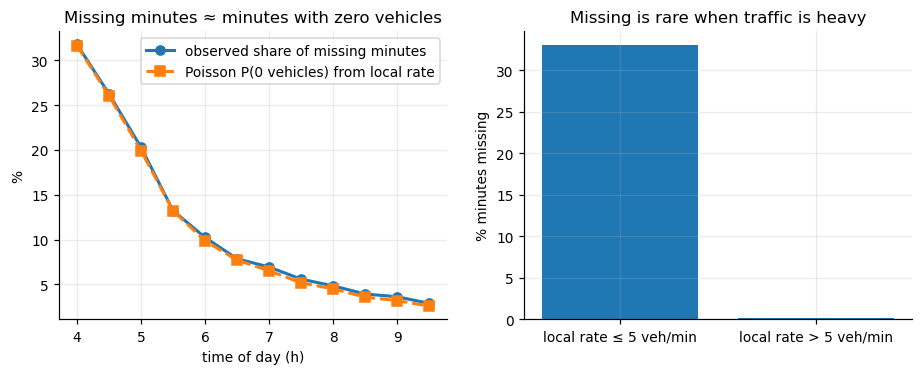

hh,4.0,4.5,5.0,5.5,6.0,6.5,7.0,7.5,8.0,8.5,9.0,9.5
observed_missing,0.318,0.263,0.203,0.132,0.102,0.079,0.069,0.056,0.048,0.039,0.036,0.029
poisson_P0,0.317,0.261,0.199,0.132,0.099,0.077,0.065,0.052,0.045,0.036,0.032,0.026


In [5]:
# use the full raw 04:00–10:00 stamps here (per-lane test, the clock offset does not matter)
r = pd.read_csv(DATA / "training_dataset.csv", sep=";").query("Time < '10:00:00'") \
      .rename(columns={"DP_ID": "sensor", "FLOW": "flow", "Date": "date"})
r["minute"] = r.Interval_1 - 240
r["date"] = pd.to_datetime(r.date.astype(str))
r["portal_km"] = r.PORTAL.str[4:].str.replace(",", ".").astype(float)
sd = r[["sensor", "date"]].drop_duplicates()
g = sd.merge(pd.DataFrame({"minute": range(360)}), how="cross") \
      .merge(r[["sensor", "date", "minute", "flow"]], how="left")
g["missing"] = g.flow.isna()
g["f0"] = g.flow.fillna(0)
# local arrival rate = 15-min centred mean of the lane (missing counted as 0)
g["lam"] = g.groupby(["sensor", "date"]).f0.transform(lambda s: s.rolling(15, center=True, min_periods=5).mean())
g["p0"] = np.exp(-g.lam)                               # Poisson P(no vehicle in 1 min)
g["hh"] = 4 + g.minute // 30 * 0.5
chk = g.groupby("hh").agg(observed_missing=("missing", "mean"), poisson_P0=("p0", "mean"))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(chk.index, chk.observed_missing * 100, "o-", lw=2, label="observed share of missing minutes")
ax[0].plot(chk.index, chk.poisson_P0 * 100, "s--", lw=2, label="Poisson P(0 vehicles) from local rate")
ax[0].set(xlabel="time of day (h)", ylabel="%", title="Missing minutes ≈ minutes with zero vehicles"); ax[0].legend()
hi = g[g.lam > 5]
ax[1].bar(["local rate ≤ 5 veh/min", "local rate > 5 veh/min"],
          [g[g.lam <= 5].missing.mean() * 100, hi.missing.mean() * 100])
ax[1].set(ylabel="% minutes missing", title="Missing is rare when traffic is heavy")
save(fig, "02_missing_vs_poisson"); plt.show()
chk.round(3).T

The observed share of missing minutes follows the Poisson zero-probability almost exactly in every half-hour, and when the local rate is
above 5 veh/min only ~0.2 % of minutes are missing. **Conclusion: MCS simply does not write a record when no vehicle passes.**
Treating those gaps as "missing" and interpolating would bias flow *upwards* (strongly at the start of the window, where ~30 % of lane-minutes are empty).

**Rule used in `clean_lane_data`:** for each run of consecutive missing minutes, compute the number of vehicles we would have
expected (other lanes at the same portal × this lane's training share; if the whole portal is silent, the lane's historical
profile). If the expected count over the run is ≥ 10, then P(all zeros) = e^-10 < 5·10⁻⁵ → **outage** (NaN). Otherwise → **FLOW = 0**
(speed undefined). A sensor with no rows at all on a day → outage.

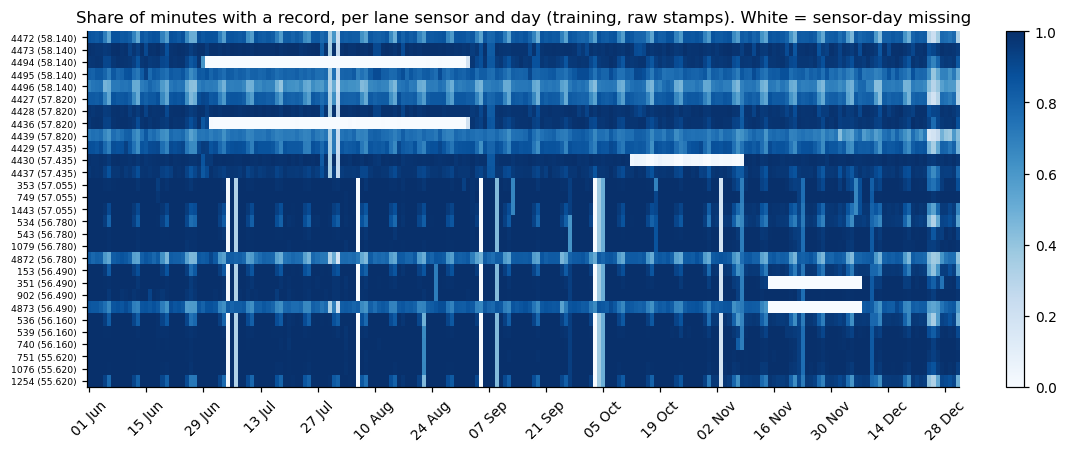

In [6]:
cov = g.groupby(["sensor", "date"]).missing.mean().unstack()
full = pd.DataFrame(1.0, index=sorted(r.sensor.unique()), columns=pd.date_range(r.date.min(), r.date.max()))
full.update(cov); cov = 1 - full                                   # share of minutes present, 0 = no data at all
order = [s for k in tp.PORTALS_DOWNSTREAM for s in sorted(r[r.portal_km == k].sensor.unique())]
fig, ax = plt.subplots(figsize=(11, 4.2))
im = ax.imshow(cov.loc[order], aspect="auto", cmap="Blues", vmin=0, vmax=1, interpolation="nearest")
ax.set_yticks(range(len(order)), [f"{s} ({r[r.sensor==s].portal_km.iat[0]:.3f})" for s in order], fontsize=6)
xt = np.arange(0, cov.shape[1], 14); ax.set_xticks(xt, [cov.columns[i].strftime("%d %b") for i in xt], rotation=45)
ax.set_title("Share of minutes with a record, per lane sensor and day (training, raw stamps). White = sensor-day missing"); ax.grid(False)
fig.colorbar(im, ax=ax, fraction=.02); save(fig, "02_availability_heatmap"); plt.show()

## 4. Cleaning and aggregation (all three files, statistics fitted on training)

In [7]:
lane_stats = tp.fit_lane_stats(raw["training"])
lane_stats.to_json(OUT / "lane_stats.json")

lane, portal, report = {}, {}, {}
for s, d in raw.items():
    lane[s], report[s] = tp.clean_lane_data(d, lane_stats)
    portal[s] = tp.aggregate_portal(lane[s], lane_stats, res=f"{RES_MIN}min")
rep = pd.DataFrame(report)
rep.loc["share outage (% of grid)"] = ((rep.loc["outage"] + rep.loc["sensor_day_missing"]) / rep.loc["grid_rows"] * 100).round(2)
rep.loc["share zero-filled (% of grid)"] = (rep.loc["zero_filled"] / rep.loc["grid_rows"] * 100).round(2)
rep.loc["portal bins imputed-lane (%)"] = [round(portal[s].imputed.gt(0).mean() * 100, 1) for s in rep.columns]
rep.loc["portal bins still NaN (%)"] = [round(portal[s].flow_vph.isna().mean() * 100, 2) for s in rep.columns]
rep

,training,evaluation,final_evaluation
raw_rows,1344924.00,565428.00,562957.00
corrupt_rows_flow_nan,12.00,3.00,3.00
invalid_speed_set_nan,26.00,16.00,16.00
observed,1344912.00,565425.00,562954.00
sensor_day_missing,54240.00,24720.00,32880.00
zero_filled,50434.00,25588.00,22950.00
outage,39842.00,10664.00,14573.00
corrupt,12.00,3.00,3.00
grid_rows,1489440.00,626400.00,633360.00
share outage (% of grid),6.32,5.65,7.49


**Aggregation choices (in `aggregate_portal`)**

* **Portal flow** = sum of its lanes. A lane in outage is imputed from the other lanes using its training share of the portal flow,
  but only if the valid lanes normally carry ≥ 60 % of the portal volume; otherwise the portal-minute is NaN.
* **Portal speed** = flow-weighted mean of lane speeds (so a lane with 1 vehicle does not count as much as a lane with 30).
* **5-min bins**: 1-min counts are Poisson-noisy (a lane with 12 veh/min has ±3.5 veh/min pure noise). 5-min bins keep the
  dynamics relevant for a 15-min horizon while cutting noise by √5. Flow is expressed in veh/h, speed in km/h.
* A bin with > 20 % of its minutes missing is NaN; NaN gaps of ≤ 2 bins (10 min) are filled **causally**
  (last value carried forward) — linear interpolation would use the value *after* the gap, which a real-time system does not have.
  The filled series is used only for *features*; *targets* come from the un-filled series (`observed=True`), so a missing truth stays missing.
* Timestamps are the **end** of each bin, so a value stamped 07:20 is actually available at 07:20 (no look-ahead).

In [8]:
wide = {s: tp.to_wide(p) for s, p in portal.items()}                       # gap-filled (features)
wide_obs = {s: tp.to_wide(p, observed=True) for s, p in portal.items()}    # as observed (targets)
for s, w in wide.items(): w.to_csv(OUT / f"portal_{RES_MIN}min_{s}.csv")
wide["training"].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
q_p58140,10218.0,2664.4,1161.4,144.0,1692.0,3060.0,3624.0,4824.0
q_p57820,10210.0,2622.5,1160.4,138.6,1651.8,2964.0,3588.0,4812.0
q_p57435,10210.0,2659.2,1181.8,59.9,1668.0,3036.0,3624.0,5295.0
q_p57055,9825.0,2694.1,1189.7,204.0,1692.0,3072.0,3684.0,5052.0
q_p56780,9848.0,2683.8,1167.9,192.0,1704.0,3060.0,3648.0,5004.0
q_p56490,9845.0,2749.4,1233.7,168.0,1716.0,3048.0,3792.0,5299.9
q_p56160,9833.0,2544.9,1084.7,156.0,1644.0,2916.0,3432.0,4668.0
q_p55620,9852.0,2499.9,1040.0,173.7,1656.0,2856.0,3348.0,4596.0
v_p58140,10218.0,77.6,5.3,13.5,75.1,77.9,80.7,93.7
v_p57820,10210.0,74.6,6.1,10.6,71.9,75.0,78.0,89.5


## 5. Exploratory data analysis

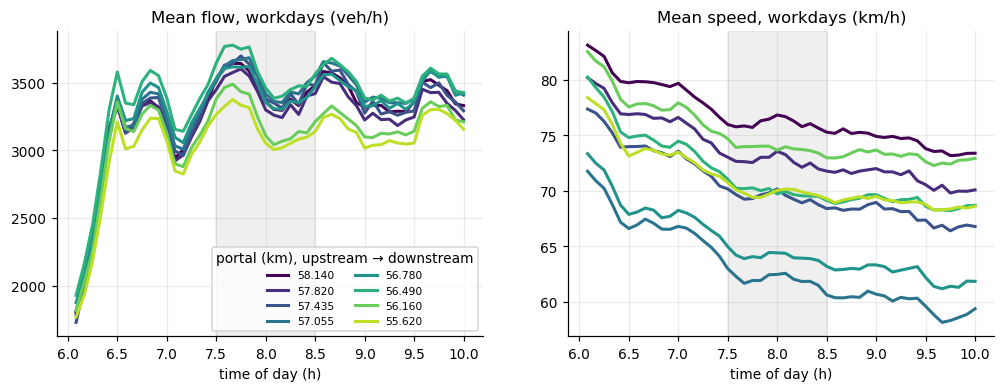

In [9]:
W = wide["training"].copy()
W["tod"] = W.index.hour + W.index.minute / 60
W["dtype"] = tp.day_type(pd.Series(W.index, index=W.index))
qcols = [f"q_{tp.PORTAL_COL[k]}" for k in tp.PORTALS_DOWNSTREAM]
vcols = [f"v_{tp.PORTAL_COL[k]}" for k in tp.PORTALS_DOWNSTREAM]
wd = W[W.dtype == "workday"]

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), sharex=True)
for k, q, v in zip(tp.PORTALS_DOWNSTREAM, qcols, vcols):
    ax[0].plot(wd.groupby("tod")[q].mean(), color=PCOL[k], lw=2, label=f"{k:.3f}")
    ax[1].plot(wd.groupby("tod")[v].mean(), color=PCOL[k], lw=2)
for a in ax: a.axvspan(7.5, 8.5, color="grey", alpha=.12)
ax[0].set(title="Mean flow, workdays (veh/h)", xlabel="time of day (h)")
ax[1].set(title="Mean speed, workdays (km/h)", xlabel="time of day (h)")
ax[0].legend(title="portal (km), upstream → downstream", fontsize=7, ncol=2)
save(fig, "04_daily_profiles"); plt.show()

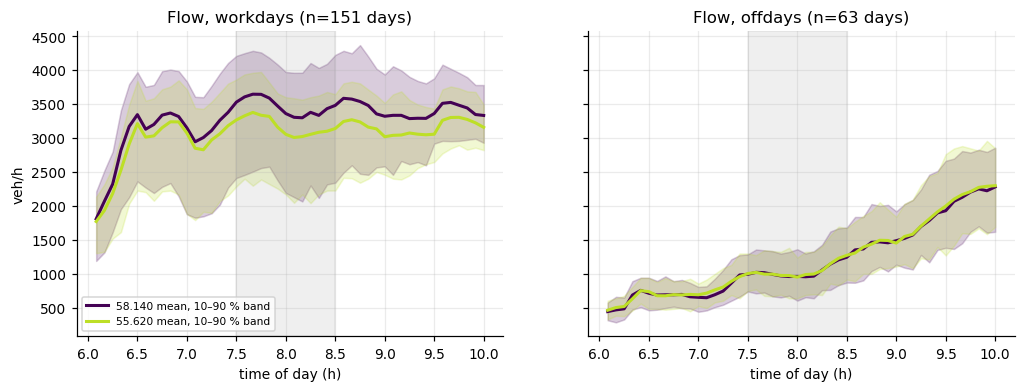

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for a, dt in zip(ax, ["workday", "offday"]):
    d = W[W.dtype == dt]
    for k, q in zip(tp.PORTALS_DOWNSTREAM[::7], qcols[::7]):
        s = d.groupby("tod")[q]
        a.fill_between(s.mean().index, s.quantile(.1), s.quantile(.9), color=PCOL[k], alpha=.2)
        a.plot(s.mean(), color=PCOL[k], lw=2, label=f"{k:.3f} mean, 10–90 % band")
    a.axvspan(7.5, 8.5, color="grey", alpha=.12); a.set(title=f"Flow, {dt}s (n={d.index.normalize().nunique()} days)", xlabel="time of day (h)")
ax[0].set_ylabel("veh/h"); ax[0].legend(fontsize=7)
save(fig, "04_workday_vs_offday"); plt.show()

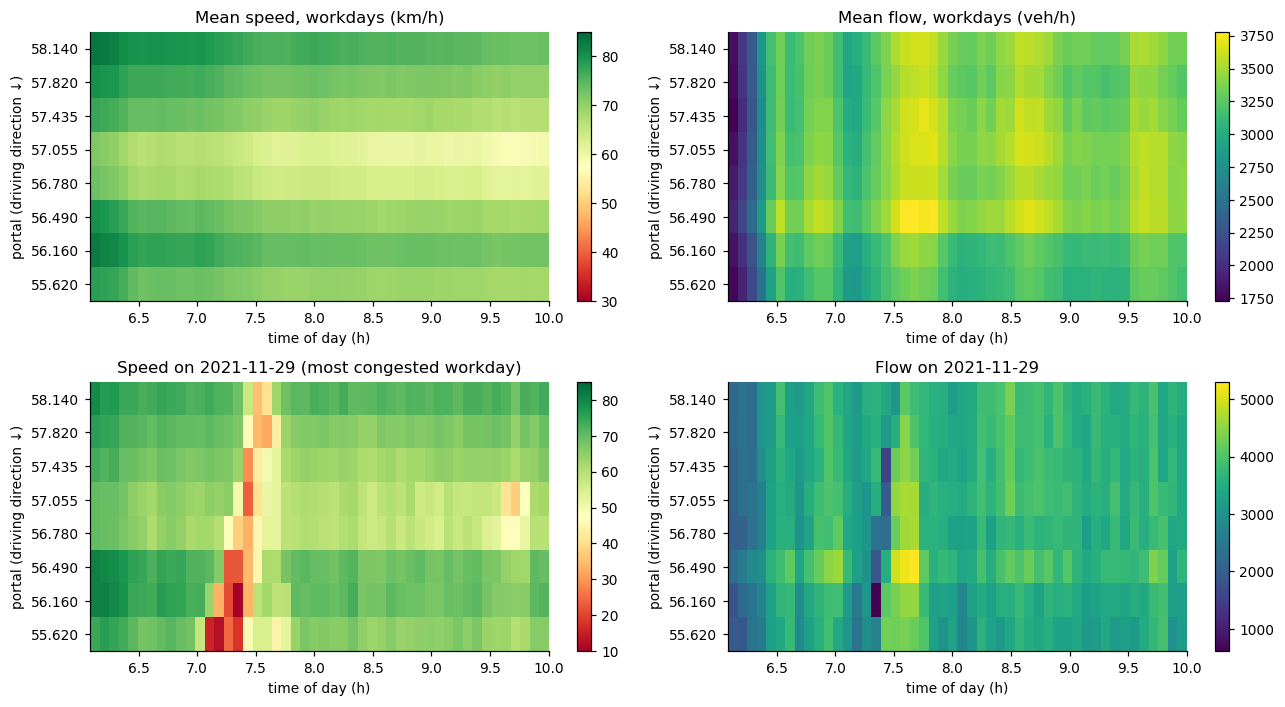

In [11]:
# Space–time diagrams (portal x time), workday average and the most congested day
def spacetime(df, col_prefix, ax, cmap, title, vmin=None, vmax=None):
    cols = [f"{col_prefix}_{tp.PORTAL_COL[k]}" for k in tp.PORTALS_DOWNSTREAM]
    m = df.groupby("tod")[cols].mean().T
    im = ax.imshow(m, aspect="auto", cmap=cmap, vmin=vmin, vmax=vmax,
                   extent=[m.columns.min(), m.columns.max(), len(cols) - .5, -.5])
    ax.set_yticks(range(len(cols)), [f"{k:.3f}" for k in tp.PORTALS_DOWNSTREAM]); ax.grid(False)
    ax.set(title=title, xlabel="time of day (h)", ylabel="portal (driving direction ↓)"); return im

daily_min_v = wd.groupby(wd.index.normalize())[vcols].min().min(axis=1)
worst = daily_min_v.idxmin()
fig, ax = plt.subplots(2, 2, figsize=(12, 6.5))
plt.colorbar(spacetime(wd, "v", ax[0, 0], "RdYlGn", "Mean speed, workdays (km/h)", 30, 85), ax=ax[0, 0])
plt.colorbar(spacetime(wd, "q", ax[0, 1], "viridis", "Mean flow, workdays (veh/h)"), ax=ax[0, 1])
one = W[W.index.normalize() == worst]
plt.colorbar(spacetime(one, "v", ax[1, 0], "RdYlGn", f"Speed on {worst.date()} (most congested workday)", 10, 85), ax=ax[1, 0])
plt.colorbar(spacetime(one, "q", ax[1, 1], "viridis", f"Flow on {worst.date()}"), ax=ax[1, 1])
fig.tight_layout(); save(fig, "04_spacetime"); plt.show()

*Read the space–time plots top-to-bottom = driving direction.* A congestion wave appears as a low-speed region that spreads **upstream**
(upwards) over time. Where it starts is the bottleneck; how far it propagates tells us which upstream portals carry
predictive information for a downstream target (and vice-versa: downstream speed drops warn upstream flow will fall).

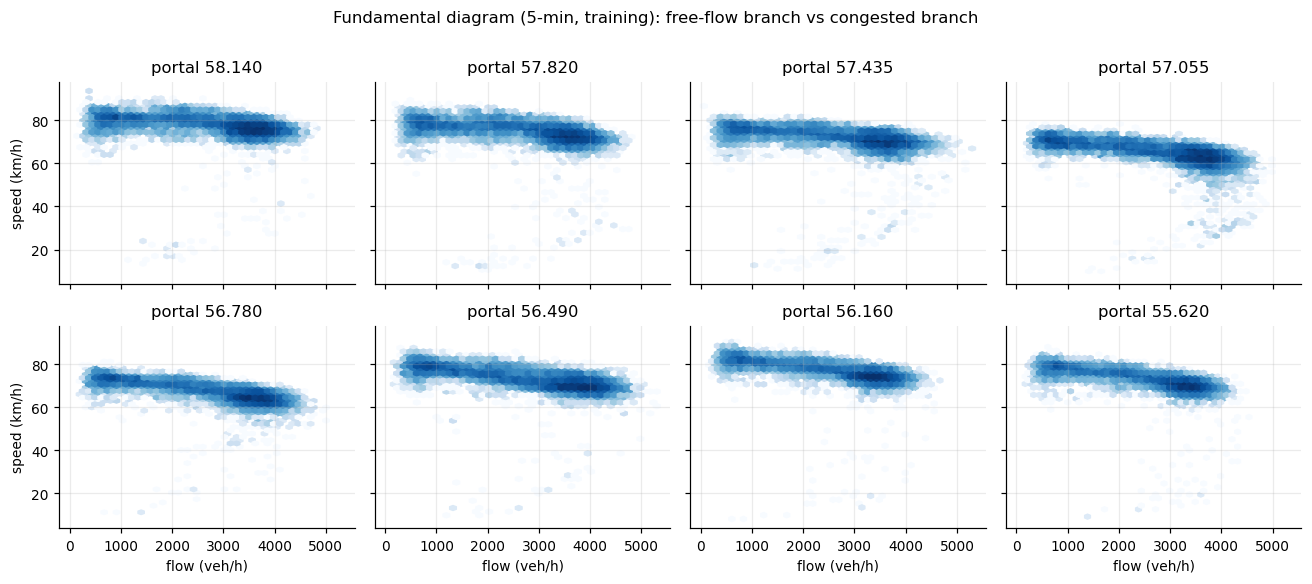

In [12]:
fig, axs = plt.subplots(2, 4, figsize=(12, 5.2), sharex=True, sharey=True)
for a, k, q, v in zip(axs.flat, tp.PORTALS_DOWNSTREAM, qcols, vcols):
    d = W[[q, v]].dropna()
    a.hexbin(d[q], d[v], gridsize=40, bins="log", cmap="Blues", mincnt=1)
    a.set_title(f"portal {k:.3f}")
for a in axs[1]: a.set_xlabel("flow (veh/h)")
for a in axs[:, 0]: a.set_ylabel("speed (km/h)")
fig.suptitle("Fundamental diagram (5-min, training): free-flow branch vs congested branch", y=1.01)
fig.tight_layout(); save(fig, "04_fundamental_diagram"); plt.show()

The flow–speed relation is **not one-to-one**: the same flow (e.g. 3 500 veh/h) occurs at 75 km/h (free flow) and at 30 km/h (congested).
A model that only sees past flow cannot know which branch it is on → **speed must be an input feature** even when the target is flow.
The top of each cloud is a practical estimate of the portal's capacity.

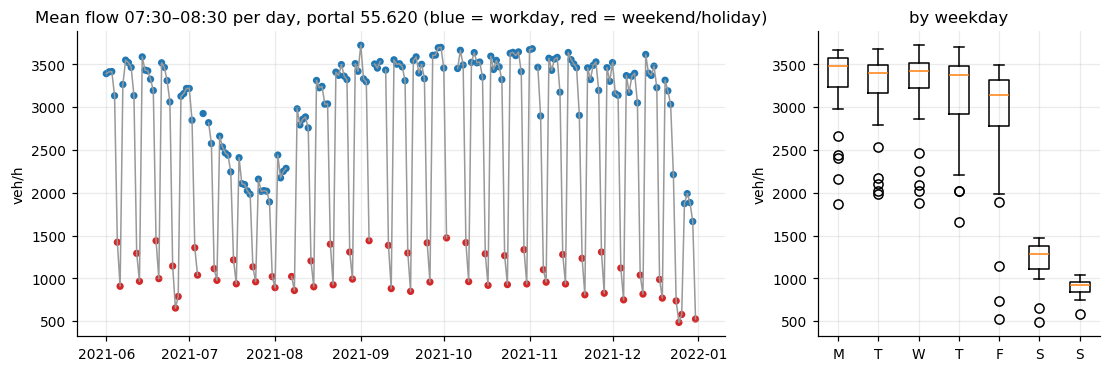

In [13]:
# day-to-day variability of the peak-hour flow and weekday effect
pk = W[(W.tod > 7.5) & (W.tod <= 8.5)]
daily = pk.groupby(pk.index.normalize())[qcols].mean()
dtype_d = tp.day_type(pd.Series(daily.index, index=daily.index))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [2.3, 1]})
c = qcols[-1]
ax[0].plot(daily.index, daily[c], color="0.6", lw=1)
ax[0].scatter(daily.index, daily[c], s=14, c=np.where(dtype_d == "workday", "C0", "C3"))
ax[0].set(title=f"Mean flow 07:30–08:30 per day, portal {tp.PORTALS_DOWNSTREAM[-1]:.3f} (blue = workday, red = weekend/holiday)", ylabel="veh/h")
ax[1].boxplot([daily[c][daily.index.dayofweek == i].dropna() for i in range(7)], labels=list("MTWTFSS"))
ax[1].set(title="by weekday", ylabel="veh/h")
save(fig, "04_daily_peak_flow"); plt.show()

Things to look for and mention in the report: the July summer-holiday dip (*industrisemester*), clearly lower weekend/holiday
flows, the Christmas week, and the fact that 2021 June–Dec differs seasonally from the 2022 Jan–Jun evaluation period.

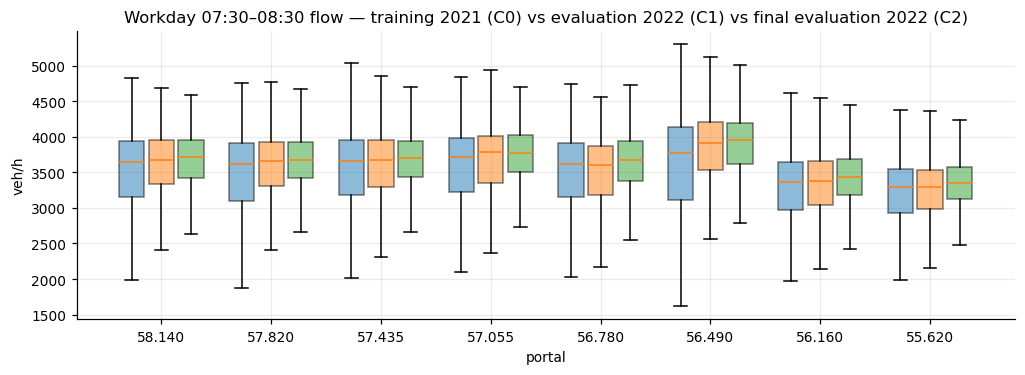

In [14]:
# distribution shift: training (2021) vs the two 2022 test files, workday peak flow per portal
fig, ax = plt.subplots(figsize=(11, 3.4))
pos = np.arange(8)
for j, (s, w) in enumerate(wide.items()):
    x = w.copy(); tod = x.index.hour + x.index.minute / 60
    x = x[(tod > 7.5) & (tod <= 8.5) & (tp.day_type(pd.Series(x.index, index=x.index)) == "workday")]
    ax.boxplot([x[q].dropna() for q in qcols], positions=pos + (j - 1) * .27, widths=.23,
               patch_artist=True, boxprops=dict(facecolor=f"C{j}", alpha=.5), showfliers=False)
ax.set_xticks(pos, [f"{k:.3f}" for k in tp.PORTALS_DOWNSTREAM]); ax.set(ylabel="veh/h", xlabel="portal",
      title="Workday 07:30–08:30 flow — training 2021 (C0) vs evaluation 2022 (C1) vs final evaluation 2022 (C2)")
save(fig, "04_distribution_shift"); plt.show()

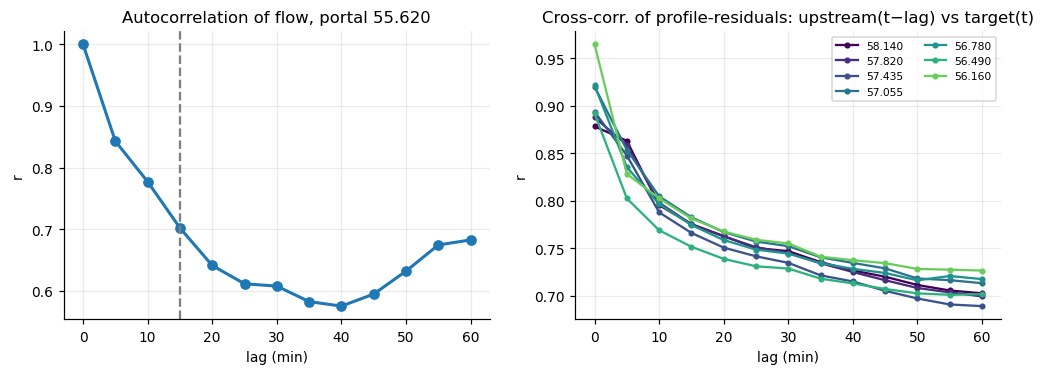

In [15]:
# temporal autocorrelation and upstream -> downstream cross-correlation (workday, 04-10)
from itertools import product
lags = range(0, 13)
tgt = qcols[-1]
def xcorr(df, a, b, L):   # corr(a(t-L), b(t)), lags taken within each day
    s = [pd.concat([d[a].shift(L), d[b]], axis=1).dropna() for _, d in df.groupby(df.index.normalize())]
    s = pd.concat(s); return np.corrcoef(s.iloc[:, 0], s.iloc[:, 1])[0, 1]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot([L * RES_MIN for L in lags], [xcorr(wd, tgt, tgt, L) for L in lags], "o-", lw=2)
ax[0].axvline(HORIZON_MIN, color="grey", ls="--"); ax[0].set(title=f"Autocorrelation of flow, portal {tp.PORTALS_DOWNSTREAM[-1]:.3f}", xlabel="lag (min)", ylabel="r")
# detrended (remove mean daily profile) so we see dynamics, not the shared morning ramp-up
res = wd[qcols + ["tod"]].copy(); res[qcols] = res[qcols] - res.groupby("tod")[qcols].transform("mean")
for k, q in zip(tp.PORTALS_DOWNSTREAM[:-1], qcols[:-1]):
    ax[1].plot([L * RES_MIN for L in lags], [xcorr(res, q, tgt, L) for L in lags], "o-", color=PCOL[k], lw=1.5, ms=3, label=f"{k:.3f}")
ax[1].set(title="Cross-corr. of profile-residuals: upstream(t−lag) vs target(t)", xlabel="lag (min)", ylabel="r"); ax[1].legend(fontsize=7, ncol=2)
save(fig, "04_auto_cross_correlation"); plt.show()

## 6. Problem formulation (draft — refine after the EDA)

* **Task:** regression. Predict the **flow (veh/h) at a target portal 15 min ahead**, `y = q(t + 15 min)`, for target times in
  **07:30–08:30** (the benchmark peak), at 5-min resolution → 13 predictions per day per portal.
* **Inputs available at time *t*** (real-time feasible — MCS data arrive each minute): recent flow & speed at the target and at the
  other portals (lags 0–30 min), short-term trend, speed differences between adjacent portals (congestion fronts), calendar
  (weekday, holiday), and a **historical-average** profile for the target time (fitted on training).
* **Baselines to beat:** persistence `ŷ = q(t)` and historical average `ŷ = hist(t+15)`. Any ML model must beat both on validation.
* **Why 15 min is reasonable in practice:** long enough for the traffic management centre / ramp metering / variable speed limits /
  travel-time signs to react, short enough that current conditions still dominate (see the autocorrelation plot).

## 7. Feature engineering

In [16]:
profile = tp.fit_profile(wide_obs["training"])              # historical average, training only
profile.to_csv(OUT / "hist_profile_training.csv")
feats = {s: tp.build_features(w, profile, horizon_min=HORIZON_MIN, res_min=RES_MIN, target_window=TARGET_WINDOW,
                              wide_obs=wide_obs[s])          # targets from the un-filled series
         for s, w in wide.items()}
F = feats["training"]
print({s: f.shape for s, f in feats.items()})
print("feature groups:", pd.Series([c.split("_")[0] for c in F.columns]).value_counts().to_dict())

{'training': (2782, 140), 'evaluation': (1170, 140), 'final_evaluation': (1183, 140)}
feature groups: {'q': 80, 'v': 32, 'y': 8, 'hist': 8, 'dv': 7, 'dow': 3, 'tod': 1, 'is': 1}


train: 167 days, 2171 rows | validation: 47 days, 611 rows


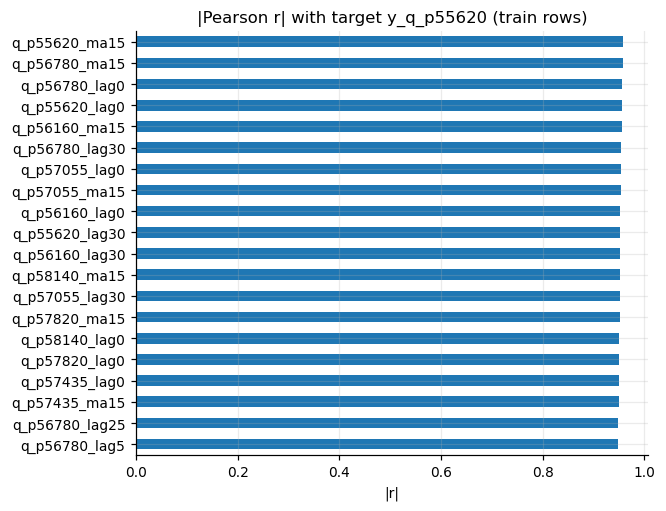

,RMSE (veh/h),MAE (veh/h)
persistence ŷ=q(t),355.0,254.0
historical average,533.0,388.0


In [17]:
# chronological split inside 2021 (no shuffling — neighbouring 5-min rows are strongly correlated)
tr = F[F.index < VAL_START]; va = F[F.index >= VAL_START]
print(f"train: {tr.index.normalize().nunique()} days, {len(tr)} rows | validation: {va.index.normalize().nunique()} days, {len(va)} rows")

y = f"y_{qcols[-1]}"
X = [c for c in F.columns if not c.startswith("y_")]
corr = tr[X + [y]].corr()[y].drop(y).abs().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(6, 5))
corr.head(20)[::-1].plot.barh(ax=ax); ax.set(title=f"|Pearson r| with target {y} (train rows)", xlabel="|r|")
save(fig, "06_feature_correlation"); plt.show()

# baselines on validation, for reference
def rmse(a, b): m = a.notna() & b.notna(); return float(np.sqrt(((a[m] - b[m]) ** 2).mean()))
def mae(a, b):  m = a.notna() & b.notna(); return float((a[m] - b[m]).abs().mean())
base = pd.DataFrame({
    "persistence  ŷ=q(t)": [rmse(va[y], va[f"{qcols[-1]}_lag0"]), mae(va[y], va[f"{qcols[-1]}_lag0"])],
    "historical average": [rmse(va[y], va[f"hist_{qcols[-1]}"]), mae(va[y], va[f"hist_{qcols[-1]}"])]},
    index=["RMSE (veh/h)", "MAE (veh/h)"]).T.round(0)
base

In [18]:
# normalisation: z-score fitted on the TRAIN rows only; calendar/binary features and targets untouched
scaler = tp.fit_scaler(tr)
scaler.to_csv(OUT / "scaler_train.csv")
parts = {"train": tr, "val": va, "evaluation": feats["evaluation"], "final_evaluation": feats["final_evaluation"]}
for name, df in parts.items():
    df.to_csv(OUT / f"features_{name}.csv")                       # unscaled (for tree models)
    tp.apply_scaler(df, scaler).to_csv(OUT / f"features_{name}_scaled.csv")   # scaled (for NN / linear)
print("NaN share per split (rows with any NaN in X or y):",
      {n: round(d.isna().any(axis=1).mean(), 3) for n, d in parts.items()})
tp.apply_scaler(tr, scaler)[scaler.index].describe().T[["mean", "std"]].round(2).head()

NaN share per split (rows with any NaN in X or y): {'train': 0.08, 'val': 0.002, 'evaluation': 0.213, 'final_evaluation': 0.311}


,mean,std
q_p58140_lag0,-0.0,1.0
q_p58140_lag5,0.0,1.0
q_p58140_lag10,0.0,1.0
q_p58140_lag15,-0.0,1.0
q_p58140_lag20,-0.0,1.0


**Notes on normalisation**

* Tree models (random forest, gradient boosting) do not need scaling → use the unscaled files.
* Linear models and neural networks: use `*_scaled.csv` (z-score with *training* mean/std). The target is left in veh/h so errors stay interpretable;
  for a NN you may additionally scale `y` (e.g. divide by 1000) and invert afterwards.
* Remaining NaNs (portal outages longer than 10 min): XGBoost takes them as they are; for ridge / NN use `tp.impute_features()`
  (causal, fitted on train) + the `*_filled` / missing flags. Rows with a missing **target** are never imputed — they are excluded
  from training and scoring, and the number of scored rows is reported. Rows with missing **inputs** are never dropped in evaluation.

## Next steps
1. Pick the target portal(s) from the space–time plot (bottleneck / most variable) — currently the downstream-most portal.
2. Models → `02_modelling.ipynb`: baselines, ridge, XGBoost, Keras MLP, evaluation and diagnostics.
3. Diagnostics: errors by time of day, workday vs off-day, congested vs free-flow, and on the 2022 evaluation file (seasonal shift).